# 05. Porto Alegre: simulação vs malha real

O Aeroporto Salgado Filho (SBPA) fechou na noite de 3 de maio de 2024, durante as enchentes do Rio Grande do Sul. Este notebook compara três redes:

| Rede | O que representa |
|---|---|
| abril (intacta) | a malha antes do fechamento |
| simulada | a malha de abril com o Salgado Filho removido: o que o modelo estático prevê |
| real | a malha que de fato operou de 04/05 a 30/06/2024 |

**H4** (`docs/problema.md`): a simulação estática superestima o dano de fechar POA, porque não captura a realocação de voos para aeroportos próximos.
*Refutada se* as métricas da rede real forem iguais ou piores que as da rede de abril com POA removido.

**Conteúdo do curso usado neste notebook**

| Conceito | Semana | Seção |
|---|---|---|
| Grau | 2 | 4 |
| Subredes | 2 | 4 |
| Componentes (SCC) | 4 | 2 e 3 |
| Eficiência | 4 | 2 |
| BFS, caminhos e distâncias | 3 e 4 | 5 |

In [1]:
import sys
from pathlib import Path
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(raiz / "src"))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

from metricas import eficiencia_entre, escalas_entre_capitais, fracao_na_maior_scc
from rede import CAPITAIS, carregar_grafo, nome_curto

PASTA_FIG = raiz / "figures"
PASTA_FIG.mkdir(exist_ok=True)

CORES = {"abril (intacta)": "#a3a29b", "simulada (abril sem POA)": "#2a78d6", "real (04/05 a 30/06)": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 3)

G_ref = carregar_grafo(raiz / "data" / "processed" / "rede_referencia.graphml")
G_real = carregar_grafo(raiz / "data" / "processed" / "rede_pos_fechamento.graphml")
G_sim = G_ref.copy()
G_sim.remove_node("SBPA")
redes = dict(zip(CORES, [G_ref, G_sim, G_real]))

def nome(icao):
    return nome_curto(G_ref if icao in G_ref else G_real, icao)

def municipio(icao):
    G = G_ref if icao in G_ref else G_real
    partes = G.nodes[icao]["nome"].split(" - ")
    palavras = [p if p in ("de", "da", "do", "das", "dos") else p.capitalize() for p in partes[-3].lower().split()]
    return f"{' '.join(palavras)} ({partes[-2]})"

for rotulo, G in redes.items():
    print(f"{rotulo}: {G.number_of_nodes()} aeroportos, {G.number_of_edges()} rotas")

abril (intacta): 154 aeroportos, 816 rotas
simulada (abril sem POA): 153 aeroportos, 776 rotas
real (04/05 a 30/06): 153 aeroportos, 806 rotas


## 1. Quais aeroportos mudaram entre as duas janelas

In [2]:
so_abril = sorted(set(G_ref) - set(G_real))
so_real = sorted(set(G_real) - set(G_ref))
print("aeroportos com voos regulares em abril, mas não em maio e junho:")
for a in so_abril:
    print(f"   {a}  {municipio(a)}")
print("aeroportos com voos regulares em maio e junho, mas não em abril:")
for a in so_real:
    print(f"   {a}  {municipio(a)}")

aeroportos com voos regulares em abril, mas não em maio e junho:
   SBBG  Bagé (RS)
   SBPA  Porto Alegre (RS)
   SNRJ  Brejo (PA)
   SSCN  Canela (RS)
   SSLT  Alegrete (RS)
   SSZR  Santa Rosa (RS)
aeroportos com voos regulares em maio e junho, mas não em abril:
   SBCO  Canoas (RS)
   SBTC  Una (BA)
   SDOW  Ourilândia do Norte (PA)
   SNCL  Cairu (BA)
   SNWS  Crateús (CE)


- Saíram da malha regular **o Salgado Filho e quatro aeroportos gaúchos**: Bagé, Canela, Alegrete e Santa Rosa. Saiu também Brejo (PA), sem relação com POA.
- Entrou **Canoas (SBCO)**, a base aérea da região metropolitana de Porto Alegre, que passou a receber voos comerciais. Entraram também quatro aeroportos do Nordeste e do Pará, sem relação com POA.
- Como as redes não têm os mesmos aeroportos, compará-las diretamente seria injusto. Medir só os aeroportos presentes nas duas também seria, porque os quatro gaúchos que perderam todos os voos ficariam de fora, e a malha real pareceria melhor do que foi.

## 2. Comparação justa: H4 (Sem. 4)

A base de comparação são **os 153 aeroportos de abril, menos o Salgado Filho**. Em cada rede, medimos a eficiência e a fração na maior SCC só entre eles (funções `eficiencia_entre` e `fracao_na_maior_scc` em `src/metricas.py`). Os caminhos podem passar por qualquer aeroporto, inclusive Canoas, e um aeroporto da base que ficou sem voos conta como isolado.

In [3]:
base = set(G_ref) - {"SBPA"}
ef_intacta = eficiencia_entre(G_ref, base)
comparacao = pd.DataFrame({
    rotulo: {
        "eficiência": eficiencia_entre(G, base),
        "variação da eficiência (%)": 100 * (eficiencia_entre(G, base) / ef_intacta - 1),
        "fração na maior SCC": fracao_na_maior_scc(G, base),
        "aeroportos fora da maior SCC ou sem voos": len(base) - round(fracao_na_maior_scc(G, base) * len(base)),
    }
    for rotulo, G in redes.items()
}).T
print(f"base de comparação: {len(base)} aeroportos (os de abril, menos o Salgado Filho)")
comparacao

base de comparação: 153 aeroportos (os de abril, menos o Salgado Filho)


,eficiência,variação da eficiência (%),fração na maior SCC,aeroportos fora da maior SCC ou sem voos
abril (intacta),0.389,0.000,0.993,1.0
simulada (abril sem POA),0.364,-6.499,0.954,7.0
real (04/05 a 30/06),0.372,-4.413,0.967,5.0


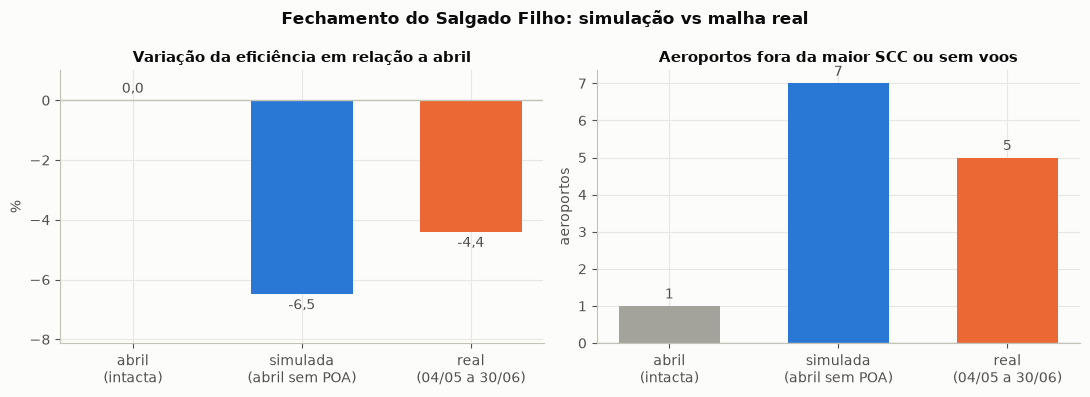

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, medida, titulo in [(eixos[0], "variação da eficiência (%)", "Variação da eficiência em relação a abril"),
                           (eixos[1], "aeroportos fora da maior SCC ou sem voos", "Aeroportos fora da maior SCC ou sem voos")]:
    valores = comparacao[medida]
    barras = ax.bar(range(len(valores)), valores, color=list(CORES.values()), width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f}".replace(".", ",") if "eficiência" in medida else f"{v:.0f}" for v in valores],
                 padding=3, color="#52514e")
    ax.set_xticks(range(len(valores)), [r.replace(" (", "\n(") for r in valores.index])
    ax.set_title(titulo)
    ax.axhline(0, color="#c3c2b7", linewidth=1)
eixos[0].set_ylabel("%")
eixos[1].set_ylabel("aeroportos")
eixos[0].set_ylim(comparacao["variação da eficiência (%)"].min() * 1.25, 1)
fig.suptitle("Fechamento do Salgado Filho: simulação vs malha real", fontweight="bold")
fig.tight_layout()
fig.savefig(PASTA_FIG / "05_simulado_vs_real.png", dpi=150)
plt.show()

- A simulação previa uma **perda de 6,5% na eficiência**. A malha real perdeu **4,4%**: cerca de **um terço do dano previsto não aconteceu**.
- A simulação previa **6 aeroportos gaúchos desconectados**. Na realidade, **4** perderam a ligação (todos os voos). Os outros números da figura incluem casos sem relação com POA: Iguatu (CE), fora da SCC em abril, e Brejo (PA), sem voos em maio e junho.
- **Veredito sobre H4: confirmada.** As métricas da rede real são melhores que as da rede simulada: o modelo estático superestimou o dano.

Figura salva em `figures/05_simulado_vs_real.png`.

## 3. Os aeroportos que a simulação desconectava

In [5]:
scc_ref = max(nx.strongly_connected_components(G_ref), key=len)
scc_sim = max(nx.strongly_connected_components(G_sim), key=len)
scc_real = max(nx.strongly_connected_components(G_real), key=len)
previstos = sorted(scc_ref - scc_sim - {"SBPA"})

def vizinhos(G, a):
    return ", ".join(sorted(nome(v) for v in set(G.predecessors(a)) | set(G.successors(a))))

destino_real = pd.DataFrame({
    "aeroporto": [municipio(a) for a in previstos],
    "vizinhos em abril": [vizinhos(G_ref, a) for a in previstos],
    "situação real (mai-jun)": ["sem voos regulares" if a not in G_real else
                                ("na maior SCC" if a in scc_real else "fora da maior SCC") for a in previstos],
    "vizinhos em mai-jun": [vizinhos(G_real, a) if a in G_real else "" for a in previstos],
}, index=previstos)
with pd.option_context("display.max_colwidth", None):
    display(destino_real)

,aeroporto,vizinhos em abril,situação real (mai-jun),vizinhos em mai-jun
SBBG,Bagé (RS),Salgado Filho (RS),sem voos regulares,
SBSM,Santa Maria (RS),Salgado Filho (RS),na maior SCC,"Hercílio Luz (SC), Viracopos (SP)"
SBUG,Uruguaiana (RS),Salgado Filho (RS),na maior SCC,Afonso Pena (PR)
SSCN,Canela (RS),Salgado Filho (RS),sem voos regulares,
SSLT,Alegrete (RS),Salgado Filho (RS),sem voos regulares,
SSZR,Santa Rosa (RS),Salgado Filho (RS),sem voos regulares,


- A simulação acertou **quais aeroportos estavam em risco**: os 6 só se ligavam ao país pelo Salgado Filho.
- Para **4 deles (Bagé, Canela, Alegrete e Santa Rosa), a previsão se confirmou**, e até foi além: eles não só saíram da maior SCC, como deixaram de ter voos regulares.
- **2 foram religados a outros hubs**, algo que o modelo estático não tinha como prever: **Santa Maria** passou a voar para Florianópolis e Viracopos, e **Uruguaiana**, para Curitiba.

## 4. A sub-rede do Sul antes e depois (Sem. 2)

In [6]:
uf = lambda a: (G_ref if a in G_ref else G_real).nodes[a]["nome"].split(" - ")[-2]
sul = sorted({a for G in (G_ref, G_real) for a in G if uf(a) in ("RS", "SC")})
tabela_sul = pd.DataFrame({
    "aeroporto": [municipio(a) for a in sul],
    "grau abril": [G_ref.degree(a) if a in G_ref else 0 for a in sul],
    "grau mai-jun": [G_real.degree(a) if a in G_real else 0 for a in sul],
    "vizinhos ganhos": [", ".join(sorted(nome(v) for v in (set(nx.all_neighbors(G_real, a)) if a in G_real else set())
                                          - (set(nx.all_neighbors(G_ref, a)) if a in G_ref else set()))) for a in sul],
    "vizinhos perdidos": [", ".join(sorted(nome(v) for v in (set(nx.all_neighbors(G_ref, a)) if a in G_ref else set())
                                            - (set(nx.all_neighbors(G_real, a)) if a in G_real else set()))) for a in sul],
}, index=sul).sort_values("grau abril", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(tabela_sul)

,aeroporto,grau abril,grau mai-jun,vizinhos ganhos,vizinhos perdidos
SBPA,Porto Alegre (RS),40,0,,"Afonso Pena (PR), Brasília (DF), Canela (RS), Cataratas (PR), Comandante Gustavo Kraemer (RS), Congonhas (SP), Galeão (RJ), Gaudêncio Machado Ramos (RS), Guararapes (PE), Guarulhos (SP), Hercílio Luz (SC), Lauro Carneiro de Loyola (SC), Ministro Victor Konder (SC), Pelotas (RS), Rubem Berta (RS), Santa Maria (RS), Santa Rosa (RS), Santo Ângelo (RS), Tancredo Neves (MG), Viracopos (SP)"
SBFL,Florianópolis (SC),20,22,"Pelotas (RS), Santa Maria (RS)",Salgado Filho (RS)
SBNF,Navegantes (SC),10,8,,Salgado Filho (RS)
SBCH,Chapecó (SC),8,8,,
SBJV,Joinville (SC),8,6,,Salgado Filho (RS)
SBCX,Caxias do Sul (RS),6,8,Galeão (RJ),
SBPK,Pelotas (RS),4,6,"Hercílio Luz (SC), Viracopos (SP)",Salgado Filho (RS)
SBJA,Jaguaruna (SC),4,4,,
SBNM,Santo Ângelo (RS),4,4,Viracopos (SP),Salgado Filho (RS)
SBPF,Passo Fundo (RS),4,4,,


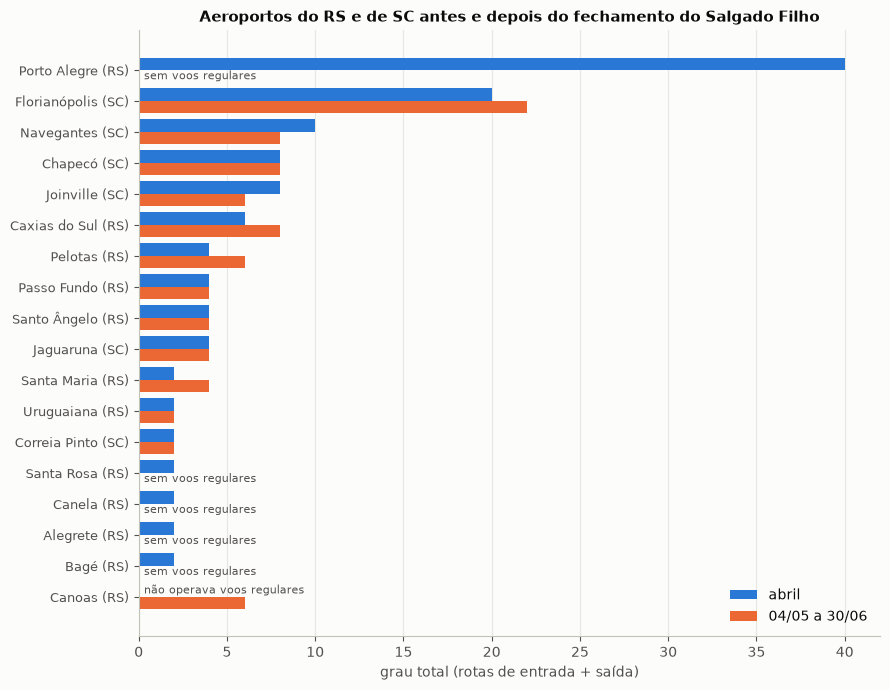

In [7]:
t = tabela_sul.sort_values(["grau abril", "grau mai-jun"])
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(y + 0.2, t["grau abril"], height=0.4, color="#2a78d6", label="abril")
ax.barh(y - 0.2, t["grau mai-jun"], height=0.4, color="#eb6834", label="04/05 a 30/06")
ax.set_yticks(y, t["aeroporto"], fontsize=9)
for i, (abril, depois) in enumerate(zip(t["grau abril"], t["grau mai-jun"])):
    if depois == 0:
        ax.text(0.3, i - 0.2, "sem voos regulares", va="center", fontsize=8, color="#52514e")
    if abril == 0:
        ax.text(0.3, i + 0.2, "não operava voos regulares", va="center", fontsize=8, color="#52514e")
ax.set(title="Aeroportos do RS e de SC antes e depois do fechamento do Salgado Filho",
       xlabel="grau total (rotas de entrada + saída)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(PASTA_FIG / "05_sul_antes_depois.png", dpi=150)
plt.show()

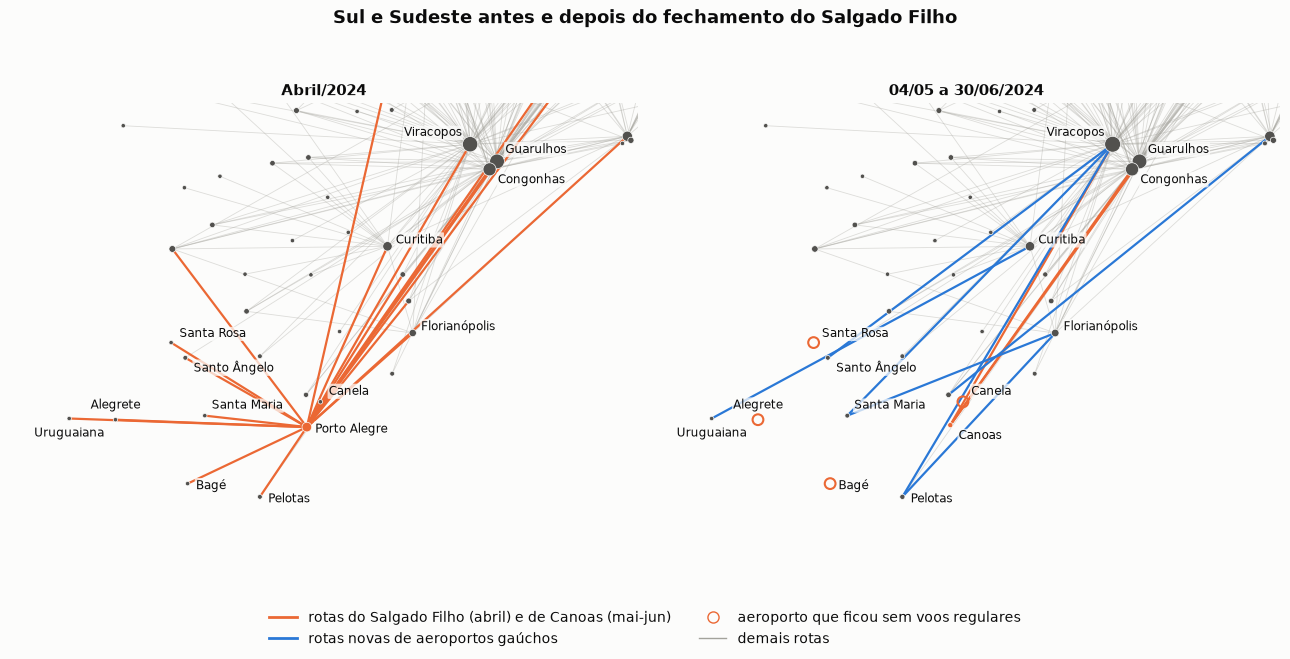

rotas novas de aeroportos gaúchos: ['Afonso Pena (PR) - Rubem Berta (RS)', 'Galeão (RJ) - Regional Hugo Cantergiani (RS)', 'Hercílio Luz (SC) - Pelotas (RS)', 'Hercílio Luz (SC) - Santa Maria (RS)', 'Viracopos (SP) - Pelotas (RS)', 'Viracopos (SP) - Santa Maria (RS)', 'Viracopos (SP) - Santo Ângelo (RS)']


In [8]:
from matplotlib.lines import Line2D

LARANJA, AZUL, CINZA = "#eb6834", "#2a78d6", "#a3a29b"
pos = {}
for G in (G_ref, G_real):
    pos.update({n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in G})
sem_voos = [a for a in so_abril if uf(a) == "RS" and a != "SBPA"]
gauchos = {a for G in (G_ref, G_real) for a in G if uf(a) == "RS"}
rotas_novas = [(u, v) for u, v in G_real.to_undirected().edges
               if (u in gauchos or v in gauchos) and not (G_ref.has_edge(u, v) or G_ref.has_edge(v, u))
               and "SBCO" not in (u, v)]
# (texto, deslocamento x, deslocamento y, alinhamento)
destaque = {"SBPA": ("Porto Alegre", 6, -4, "left"), "SBCO": ("Canoas", 6, -10, "left"),
            "SBGR": ("Guarulhos", 6, 6, "left"), "SBKP": ("Viracopos", -6, 6, "right"),
            "SBSP": ("Congonhas", 6, -10, "left"), "SBCT": ("Curitiba", 6, 2, "left"),
            "SBFL": ("Florianópolis", 6, 2, "left"), "SBSM": ("Santa Maria", 5, 5, "left"),
            "SBUG": ("Uruguaiana", 0, -13, "center"), "SBPK": ("Pelotas", 6, -4, "left"),
            "SBBG": ("Bagé", 6, -4, "left"), "SSCN": ("Canela", 6, 5, "left"),
            "SSLT": ("Alegrete", 0, 8, "center"), "SSZR": ("Santa Rosa", 6, 4, "left"),
            "SBNM": ("Santo Ângelo", 6, -10, "left")}

fig, eixos = plt.subplots(1, 2, figsize=(13, 6.6))
for ax, G, titulo, hub in [(eixos[0], G_ref, "Abril/2024", "SBPA"),
                           (eixos[1], G_real, "04/05 a 30/06/2024", "SBCO")]:
    U = G.to_undirected()
    do_hub = [e for e in U.edges if hub in e]
    novas = rotas_novas if G is G_real else []
    outras = [e for e in U.edges if hub not in e and e not in novas]
    nx.draw_networkx_edges(U, pos, edgelist=outras, ax=ax, edge_color=CINZA, alpha=0.35, width=0.6)
    nx.draw_networkx_edges(U, pos, edgelist=do_hub, ax=ax, edge_color=LARANJA, width=1.6)
    nx.draw_networkx_edges(U, pos, edgelist=novas, ax=ax, edge_color=AZUL, width=1.6)
    nx.draw_networkx_nodes(U, pos, ax=ax, node_size=[8 + 2 * U.degree(n) for n in U],
                           node_color=[LARANJA if n == hub else "#52514e" for n in U], edgecolors="#fcfcfb", linewidths=0.5)
    if G is G_real:
        ax.scatter([pos[a][0] for a in sem_voos], [pos[a][1] for a in sem_voos], s=60,
                   facecolors="none", edgecolors=LARANJA, linewidths=1.5, zorder=3)
    for n, (texto, dx, dy, ha) in destaque.items():
        if n in pos and (n in G or (G is G_real and n in sem_voos)):
            ax.annotate(texto, pos[n], xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8.5,
                        color="#0b0b0b", bbox=dict(boxstyle="round,pad=0.1", fc="#fcfcfb", ec="none", alpha=0.75))
    ax.set_xlim(-58.5, -43)
    ax.set_ylim(-33, -22)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, fontweight="bold")

legenda = [Line2D([], [], color=LARANJA, linewidth=2, label="rotas do Salgado Filho (abril) e de Canoas (mai-jun)"),
           Line2D([], [], color=AZUL, linewidth=2, label="rotas novas de aeroportos gaúchos"),
           Line2D([], [], marker="o", linestyle="", markersize=8, markerfacecolor="none",
                  markeredgecolor=LARANJA, label="aeroporto que ficou sem voos regulares"),
           Line2D([], [], color=CINZA, linewidth=1, label="demais rotas")]
fig.legend(handles=legenda, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Sul e Sudeste antes e depois do fechamento do Salgado Filho", fontweight="bold", fontsize=13)
fig.tight_layout(rect=(0, 0.08, 1, 0.97))
fig.savefig(PASTA_FIG / "05_mapa_antes_depois.png", dpi=150)
plt.show()

print("rotas novas de aeroportos gaúchos:", sorted(f"{nome(u)} - {nome(v)}" for u, v in rotas_novas))

- **Canoas não substituiu o Salgado Filho.** Com grau 6, ela só se liga a Guarulhos, Congonhas e Viracopos, enquanto o Salgado Filho tinha grau 40 e 20 vizinhos. Canoas assumiu as ligações com São Paulo, não as regionais nem as ligações diretas com outras capitais.
- **Florianópolis virou a alternativa regional:** ganhou rotas para Pelotas e Santa Maria e passou de grau 20 para 22.
- Outros aeroportos gaúchos ganharam ligações diretas com hubs fora do estado: **Pelotas** (Florianópolis e Viracopos), **Santo Ângelo** (Viracopos), **Caxias do Sul** (Galeão) e **Uruguaiana** (Curitiba).
- Navegantes e Joinville perderam a rota para Porto Alegre e não ganharam outra.
- A malha se reorganizou **para fora do estado**: o interior gaúcho, que antes passava por Porto Alegre, passou a se ligar diretamente a Florianópolis, Curitiba e aos hubs de São Paulo.

- **No mapa**, a mudança fica visível: o leque laranja do Salgado Filho, que ligava o interior gaúcho e várias capitais, dá lugar a três rotas de Canoas para São Paulo; as rotas azuis mostram o interior religado a Florianópolis, Curitiba e Viracopos; e os círculos vazios marcam os quatro aeroportos que ficaram sem voos.

Figuras salvas em `figures/05_sul_antes_depois.png` e `figures/05_mapa_antes_depois.png`.

## 5. Escalas entre capitais (Sem. 3 e 4)

Na malha real, Porto Alegre é representada por Canoas (opção b do `docs/modelagem.md`). Na simulada, a capital fica sem aeroporto.

In [9]:
escalas_ref = escalas_entre_capitais(G_ref, CAPITAIS)
capitais_real = {**CAPITAIS, "Porto Alegre": ["SBCO"]}
escalas_real = escalas_entre_capitais(G_real, capitais_real)

poa = pd.DataFrame({
    "abril (Salgado Filho)": escalas_ref.loc["Porto Alegre"],
    "mai-jun (Canoas)": escalas_real.loc["Porto Alegre"],
}).drop("Porto Alegre")
print("escalas de Porto Alegre até as outras capitais:")
display(poa.apply(pd.Series.value_counts).fillna(0).astype(int).rename_axis("escalas"))
print("capitais com voo direto em abril:", sorted(poa.index[poa["abril (Salgado Filho)"] == 0]))
print("capitais com voo direto em mai-jun:", sorted(poa.index[poa["mai-jun (Canoas)"] == 0]))
print("capitais a 2 escalas em mai-jun:", sorted(poa.index[poa["mai-jun (Canoas)"] == 2]))

escalas de Porto Alegre até as outras capitais:


,abril (Salgado Filho),mai-jun (Canoas)
escalas,,
0.0,7,1
1.0,19,23
2.0,0,2


capitais com voo direto em abril: ['Belo Horizonte', 'Brasília', 'Curitiba', 'Florianópolis', 'Recife', 'Rio de Janeiro', 'São Paulo']
capitais com voo direto em mai-jun: ['São Paulo']
capitais a 2 escalas em mai-jun: ['Macapá', 'Rio Branco']


In [10]:
outras = [c for c in CAPITAIS if c != "Porto Alegre"]
diferenca = (escalas_real.loc[outras, outras] - escalas_ref.loc[outras, outras]).stack().dropna()
print(f"pares entre as outras 26 capitais: {len(diferenca)}")
print(f"   mais escalas na malha real: {(diferenca > 0).sum()} -> {list(diferenca[diferenca > 0].index)}")
print(f"   menos escalas na malha real: {(diferenca < 0).sum()} -> {list(diferenca[diferenca < 0].index)}")

pares entre as outras 26 capitais: 650
   mais escalas na malha real: 1 -> [('Aracaju', 'Salvador')]
   menos escalas na malha real: 2 -> [('São Luís', 'Rio de Janeiro'), ('Rio de Janeiro', 'São Luís')]


- **Porto Alegre continuou alcançável, mas pior conectada.** Em abril, tinha voo direto para 7 capitais (Belo Horizonte, Brasília, Curitiba, Florianópolis, Recife, Rio de Janeiro e São Paulo). Por Canoas, só para **São Paulo**. Macapá e Rio Branco passaram a exigir **2 escalas**.
- Aqui a simulação errou para o lado pessimista: ela tratava a capital como inalcançável, e Canoas manteve a cidade ligada a todas as capitais.
- **Entre as outras 26 capitais, quase nada mudou**: 1 par piorou (Aracaju para Salvador) e 2 melhoraram (São Luís e Rio de Janeiro), sem relação aparente com Porto Alegre. Isso confirma o notebook 04: fechar o Salgado Filho não afeta as escalas entre as outras capitais.

## Resumo

- **H4 confirmada:** a simulação estática previa perda de 6,5% na eficiência e 6 aeroportos desconectados; a malha real perdeu 4,4% e 4 aeroportos.
- **O que o modelo acertou:** quais aeroportos dependiam de Porto Alegre, e que as escalas entre as outras capitais não mudariam.
- **O que o modelo não captura:** a adaptação. Canoas manteve Porto Alegre ligada a São Paulo, e parte do interior gaúcho foi religada a Florianópolis, Curitiba e Viracopos.
- **Para quem perdeu, a perda foi total:** Bagé, Canela, Alegrete e Santa Rosa ficaram sem voos regulares.

**Limitações desta comparação:** a janela real (maio e junho) difere de abril também por sazonalidade e por mudanças sem relação com POA (Brejo, Iguatu e os novos aeroportos do Nordeste e do Pará). A base comum de aeroportos reduz esse efeito, mas não o elimina. E a rede mede rotas, não passageiros: Canoas tinha muito menos voos que o Salgado Filho.